# LinkShield AI — Notebook 03: Logistic Regression Baseline

**Project:** LinkShield AI — AI Phishing & Malicious URL Detector for Banks
**Phase:** Phase 1, Step 3 (Person 3 deliverable)
**Author:** Person 3 (Baseline Model Development)

**Objective:** train the first working model through Person 2's leak-free interfaces and evaluate it **once** on the held-out test set.

**Phase 1 rules followed in this notebook**
- Person 2's saved split, features and preprocessor are used unchanged.
- One scikit-learn `Pipeline`; it is fitted on **training data only**.
- Fixed threshold **0.50**, positive class **phishing = 1**, confusion-matrix order **[0, 1]**.
- No hyperparameter tuning, no threshold tuning, no SHAP/LIME (Phase 2).
- URLs are inert text. Nothing is opened, resolved or requested.

The reusable logic lives in `src/train_baseline.py`; this notebook walks through it step by step.

## 0. Setup

Run from the project root or from `notebooks/`. In Google Colab, upload/clone the project folder first, then `%cd` into it and run `!pip install -r requirements.txt`.

In [1]:
import sys, json, warnings
from pathlib import Path

project_root = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
assert (project_root / "src" / "train_baseline.py").exists(), f"Project root not found from {Path.cwd()}"
sys.path.insert(0, str(project_root))

import numpy as np
import pandas as pd
import sklearn, joblib, matplotlib
import matplotlib.pyplot as plt
from IPython.display import Image, Markdown, display

from src import train_baseline as tb
from src.url_features import FEATURE_NAMES

print("Python      :", sys.version.split()[0])
print("scikit-learn:", sklearn.__version__)
print("pandas      :", pd.__version__)
print("numpy       :", np.__version__)
print("joblib      :", joblib.__version__)
print("Seed:", tb.RANDOM_STATE, "| Threshold:", tb.THRESHOLD, "| Label order:", tb.LABELS)

Python      : 3.12.10
scikit-learn: 1.8.0
pandas      : 3.0.2
numpy       : 2.4.4
joblib      : 1.5.3
Seed: 42 | Threshold: 0.5 | Label order: [0, 1]


## 1. Load Person 2's split (unchanged)

In [2]:
X_train, y_train, X_test, y_test = tb.load_split(project_root)

split_table = pd.DataFrame({
    "rows": [len(X_train), len(X_test)],
    "legitimate (0)": [(y_train == 0).sum(), (y_test == 0).sum()],
    "phishing (1)": [(y_train == 1).sum(), (y_test == 1).sum()],
    "phishing share": [f"{y_train.mean():.2%}", f"{y_test.mean():.2%}"],
}, index=["train", "test"])
split_table

,rows,legitimate (0),phishing (1),phishing share
train,188284,107880,80404,42.70%
test,47072,26970,20102,42.70%


## 2. Confirm the modelling contract before training

Checks: labels are binary with phishing = 1; zero exact and normalized URL overlap between train and test; the loaded files match Person 2's split summary; and `train.csv` / `test.csv` are exactly reproduced by a stratified 80/20 split of `cleaned_urls.csv` with seed 42 (so no new split was created).

In [3]:
checks = tb.verify_contract(X_train, y_train, X_test, y_test, project_root)
pd.Series(checks, name="result").to_frame()

,result
labels_binary,True
exact_url_overlap,0
normalized_url_overlap,0
matches_person2_split_summary,True
split_reproducible_from_cleaned_csv,True
feature_count,25
target_not_in_features,True
test_rows_with_hostname_seen_in_train,3745
test_rows_with_hostname_seen_in_train_pct,0.079559


## 3. Build the baseline Pipeline (unfitted)

In [4]:
pipeline = tb.build_baseline_pipeline()
print("Steps:", [name for name, _ in pipeline.steps])
print("Raw features from Person 2:", len(FEATURE_NAMES))
print("Classifier params:")
for k, v in pipeline.named_steps["classifier"].get_params().items():
    print(f"  {k} = {v}")

Steps: ['url_features', 'preprocessor', 'classifier']
Raw features from Person 2: 25
Classifier params:
  C = 1.0
  class_weight = balanced
  dual = False
  fit_intercept = True
  intercept_scaling = 1
  l1_ratio = 0.0
  max_iter = 1000
  n_jobs = None
  penalty = deprecated
  random_state = 42
  solver = lbfgs
  tol = 0.0001
  verbose = 0
  warm_start = False


## 4. Fit on training data only

`ConvergenceWarning`s are captured and reported, not suppressed.

In [5]:
pipeline, train_info = tb.train_baseline(X_train, y_train)
train_info

{'train_rows': 188284,
 'max_iter': 1000,
 'n_iter_used': 17,
 'converged': True,
 'convergence_warnings': [],
 'n_model_input_columns': 580}

## 5. Evaluate once on the held-out test set (threshold 0.50)

In [6]:
train_hosts = set(X_train.map(tb._hostname))
metrics = tb.evaluate(pipeline, X_test, y_test, tb.THRESHOLD, train_hostnames=train_hosts)

cm = pd.DataFrame(
    [[metrics["tn"], metrics["fp"]], [metrics["fn"], metrics["tp"]]],
    index=["Actual legitimate (0)", "Actual phishing (1)"],
    columns=["Predicted legitimate (0)", "Predicted phishing (1)"],
)
display(cm)
print(f"TN = {metrics['tn']:,}   FP = {metrics['fp']:,}   FN = {metrics['fn']:,}   TP = {metrics['tp']:,}")
print(f"Precision (phishing) : {metrics['precision_phishing']:.6f}")
print(f"Recall    (phishing) : {metrics['recall_phishing']:.6f}")
print(f"F1        (phishing) : {metrics['f1_phishing']:.6f}")
print(f"Accuracy (supplementary): {metrics['accuracy']:.6f}")
print(f"ROC-AUC  (supplementary): {metrics['roc_auc']:.6f}")

,Predicted legitimate (0),Predicted phishing (1)
Actual legitimate (0),26969,1
Actual phishing (1),94,20008


TN = 26,969   FP = 1   FN = 94   TP = 20,008
Precision (phishing) : 0.999950
Recall    (phishing) : 0.995324
F1        (phishing) : 0.997632
Accuracy (supplementary): 0.997982
ROC-AUC  (supplementary): 0.998864


### Reading the confusion matrix for a bank security team

- **FN** (phishing scored as legitimate) is the costly error: phishing gets through.
- **FP** (legitimate scored as phishing) costs analyst review time and may block genuine links.
- Precision = TP / (TP + FP); Recall = TP / (TP + FN); F1 balances the two. Accuracy is supplementary only.

## 6. Diagnostic: test rows whose hostname never appears in training

Person 2's audit reported hostname overlap between train and test. The same predictions are re-scored on the unseen-hostname subset only (the split itself is not changed).

In [7]:
sub = metrics["unseen_hostname_subset"]
pd.DataFrame({
    "all test rows": [metrics["test_rows"], metrics["precision_phishing"], metrics["recall_phishing"], metrics["f1_phishing"], metrics["fp"], metrics["fn"]],
    "hostname unseen in training": [sub["rows"], sub["precision_phishing"], sub["recall_phishing"], sub["f1_phishing"], sub["fp"], sub["fn"]],
}, index=["rows", "precision", "recall", "F1", "FP", "FN"]).T

,rows,precision,recall,F1,FP,FN
all test rows,47072.0,0.999950,0.995324,0.997632,1.0,94.0
hostname unseen in training,43327.0,0.999939,0.998778,0.999358,1.0,20.0


## 7. Sanity check: how separable is this dataset?

A near-perfect baseline score needs an explanation. The cell below measures, on the **training** data, how often each class has a few simple URL properties, and scores a one-line rule with no machine learning as a reference point.

In [8]:
artifact_check = tb.dataset_artifact_check(X_train, y_train, X_test, y_test)
shares = pd.DataFrame(artifact_check["train_share_of_urls_where"]).T
display(shares.apply(lambda col: col.map("{:.2%}".format)))
print("Trivial rule:", artifact_check["trivial_rule"])
r = artifact_check["trivial_rule_test_scores"]
print(f"  test precision = {r['precision_phishing']:.4f}, recall = {r['recall_phishing']:.4f}, F1 = {r['f1_phishing']:.4f}")
print(f"Logistic Regression baseline F1 = {metrics['f1_phishing']:.4f}")

,legitimate,phishing
scheme_is_https,100.00%,48.53%
hostname_starts_with_www,100.00%,41.53%
path_longer_than_slash,0.00%,27.18%
has_query_string,0.00%,6.01%


Trivial rule: predict phishing unless the URL is https AND starts with www.
  test precision = 1.0000, recall = 0.9772, F1 = 0.9885
Logistic Regression baseline F1 = 0.9976


**Interpretation.** In this benchmark every legitimate URL is a bare `https://www.<host>` home page, so a trivial rule already scores very highly. The baseline's result is real and leak-free, but it mostly reflects how the dataset was collected. It must not be presented as real-world phishing-detection ability, and the model will flag ordinary legitimate deep links (see Section 10).

## 8. Which features the linear model leans on

In [9]:
coef = tb.top_coefficients(pipeline)
display(pd.DataFrame(coef["numeric_pushing_towards_phishing"]).rename(columns={"feature": "pushes towards phishing"}))
display(pd.DataFrame(coef["numeric_pushing_towards_legitimate"]).rename(columns={"feature": "pushes towards legitimate"}))

,pushes towards phishing,coefficient
0,num__num_slashes,12.551288
1,num__num_digits,7.181981
2,num__num_special_chars,2.916386
3,num__path_length,0.690658
4,num__url_length,0.615748
5,num__num_dots,0.575581
6,num__has_query,0.572277
7,num__query_length,0.524628


,pushes towards legitimate,coefficient
0,num__has_https,-7.411389
1,num__has_www,-5.598846
2,num__has_ip,-0.640764
3,num__num_at_symbols,-0.570013
4,num__num_subdomains,-0.322046
5,num__num_percent_signs,-0.297712
6,num__num_hyphens,-0.274179
7,num__has_fragment,-0.270509


## 9. Official run: save metrics JSON, confusion-matrix image, notes and model artifact

`run_baseline()` repeats the same steps (plus a 5-fold stability check on the **training** data, with nothing tuned from it) and writes every output file. The assertions then confirm that the saved JSON equals the values shown above.

In [10]:
saved_pipeline, report = tb.run_baseline(project_root)

saved = json.loads((project_root / tb.METRICS_JSON).read_text(encoding="utf-8"))
for key in ["tn", "fp", "fn", "tp", "precision_phishing", "recall_phishing", "f1_phishing", "accuracy"]:
    assert saved[key] == metrics[key], f"Mismatch on {key}: JSON {saved[key]} vs notebook {metrics[key]}"
assert saved["threshold"] == 0.5 and saved["positive_label"] == 1
assert saved["confusion_matrix_label_order"] == ["legitimate_0", "phishing_1"]
print("\nMetrics JSON matches the notebook output: OK")

[1/6] Loading Person 2's split ...
[2/6] Verifying the modelling contract ...


[3/6] 5-fold cross-validation on TRAINING data only ...


[4/6] Fitting the full Pipeline on TRAINING data only ...


[5/6] Evaluating once on the held-out test set at threshold 0.5 ...


[6/6] Saving outputs ...

Held-out test set, threshold 0.50, positive class = phishing (1)
  Confusion matrix [[TN, FP], [FN, TP]] = [[26969, 1], [94, 20008]]
  Precision (phishing): 1.0000
  Recall    (phishing): 0.9953
  F1        (phishing): 0.9976
  Accuracy  (supplementary): 0.9980

Metrics JSON matches the notebook output: OK


5-fold CV on training data only (fixed configuration, nothing tuned):
  precision: mean 0.9999  std 0.0001
  recall   : mean 0.9954  std 0.0005
  f1       : mean 0.9977  std 0.0002


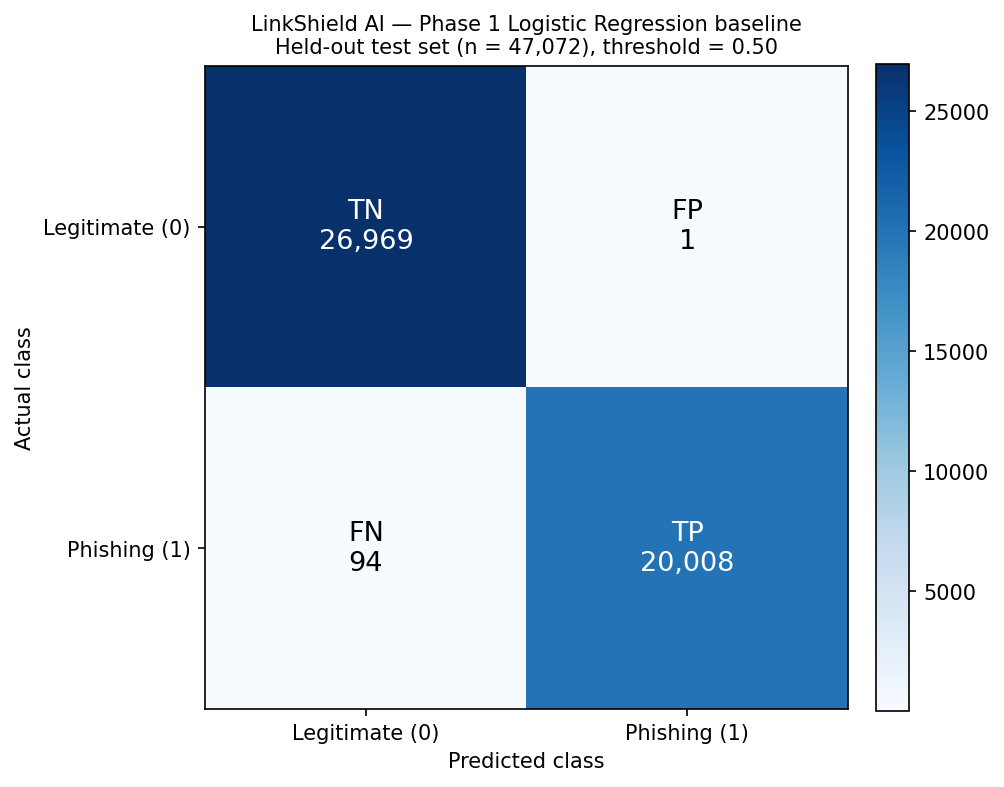

In [11]:
cv = report["cross_validation_on_train"]
print("5-fold CV on training data only (fixed configuration, nothing tuned):")
for name in ["precision", "recall", "f1"]:
    print(f"  {name:9s}: mean {cv[name + '_phishing_mean']:.4f}  std {cv[name + '_phishing_std']:.4f}")
display(Image(filename=str(project_root / tb.CONFUSION_PNG), width=520))

## 10. Reload the saved artifact and score a few inert sample strings

These strings are reserved documentation examples (`example.com`, `192.0.2.x`). They are never opened.

In [12]:
smoke = tb.smoke_test_artifact(project_root)
smoke

,url_text_inert,phishing_score,predicted_class
0,https://www.example.com,0.0027,0
1,https://www.example.org/about/team,1.0000,1
2,http://secure-login-verify.example.com/account...,1.0000,1
3,http://192.0.2.10/bank/signin/confirm.php,1.0000,1


Note the second row: an ordinary-looking `https://www.example.org/about/team` string is scored as phishing because no legitimate URL in the training data has a path. This is the dataset limitation from Section 7 showing up in practice.

## 11. Inputs for the Phase 1 business metric (for Person 4)

In [13]:
biz = report["business_metric_inputs_for_person4"]
print("Basis:", biz["basis"])
print(f"Alerts raised (TP+FP): {biz['alerts_raised_tp_plus_fp']:.1f}")
print(f"  of which false alarms (FP): {biz['of_which_false_alarms_fp']:.1f}")
print(f"Missed phishing (FN): {biz['missed_phishing_fn']:.1f}")
for k, v in biz["review_hours_by_assumed_minutes_per_alert"].items():
    print(f"Review hours at ASSUMED {k.replace('_', ' ')}/alert: {v:.1f}")
print(biz["assumption_note"])

Basis: per 10,000 screened URLs at the test-set class mix (42.7% phishing — a benchmark mix, not real bank traffic)
Alerts raised (TP+FP): 4250.7
  of which false alarms (FP): 0.2
Missed phishing (FN): 20.0
Review hours at ASSUMED 1 min/alert: 70.8
Review hours at ASSUMED 3 min/alert: 212.5
Review hours at ASSUMED 5 min/alert: 354.2
1/3/5 minutes per alert are illustrative scenarios only; no bank interview or cited source backs them.


## 12. Summary and limitations

- The Phase 1 Logistic Regression baseline is trained inside one Pipeline on training data only and evaluated once on the held-out test set at threshold 0.50.
- All numbers above are written to `reports/phase1_baseline_metrics.json`; the interpretation is in `reports/phase1_baseline_notes.md`.
- **Limitations:** public benchmark with a 42.7% phishing share (not bank traffic); legitimate URLs in the dataset are all bare home pages, so the classes are almost trivially separable; hostname overlap between train and test; URL text only; threshold and hyperparameters not tuned; no robustness or explainability work yet (Phase 2).
- The test set must not be reused to choose Phase 2 models or thresholds.